# **Data Visualization**
This notebook contains visualizations of the dataset trying to visualize relationships between features and time-series analysis. Includes analysis of each graph made.

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_parquet("../data/standardized.parquet")

# Create a completed-purchases view for transaction analysis; keep the full data unchanged.
purchases = df.loc[
    ~df["Is_Cancellation"] & df["Quantity"].gt(0)
].copy()
analysis_cols = ["Quantity", "Price", "Total_Price"]

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Shape: (776591, 24)
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Is_Cancellation', 'Total_Price', 'CustomerMonth', 'Country_grouped', 'Country_EIRE', 'Country_France', 'Country_Germany', 'Country_Netherlands', 'Country_Other', 'Country_United Kingdom', 'Quantity_log', 'Price_log', 'Total_Price_log', 'Quantity_scaled', 'Price_scaled', 'Total_Price_scaled']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Is_Cancellation,Total_Price,...,Country_Germany,Country_Netherlands,Country_Other,Country_United Kingdom,Quantity_log,Price_log,Total_Price_log,Quantity_scaled,Price_scaled,Total_Price_scaled
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,False,83.4,...,False,False,False,True,2.564949,2.073172,4.435567,0.661217,1.585922,2.002152
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,81.0,...,False,False,False,True,2.564949,2.047693,4.406719,0.661217,1.541560,1.972839
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,81.0,...,False,False,False,True,2.564949,2.047693,4.406719,0.661217,1.541560,1.972839
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,False,100.8,...,False,False,False,True,3.891820,1.131402,4.623010,2.010135,-0.053821,2.192616
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,False,30.0,...,False,False,False,True,3.218876,0.810930,3.433987,1.326009,-0.611804,0.984430


In [36]:
CHURN_WINDOW_DAYS = 90   # churned = bought before the cutoff of 90 days
HUE_ORDER = ["Retained", "Churned"]
PAL = {"Retained": "#4C72B0", "Churned": "#DD8452"} #Color palette for the graphs

In [37]:
#one row per customer from the dataframe
df = df.dropna(subset=["Customer ID"]).copy()
df["Customer ID"] = df["Customer ID"].astype(int) #change object to integer
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"]) #convert to datetime format
df["Revenue"] = df["Total_Price"]                    # revenue per line item
df["is_cancel"] = df["Is_Cancellation"].astype(bool)  # cancelled/returned lines
 
# Features come only from before the cutoff of 90 days,  churn label comes from after it
cutoff = df["InvoiceDate"].max() - pd.Timedelta(days=CHURN_WINDOW_DAYS)
obs = df[df["InvoiceDate"] <= cutoff] # observations before the cutoff
obs_p = obs[~obs["is_cancel"]] # observations before the cutoff that are NOT cancelled
future_ids = df.loc[(df["InvoiceDate"] > cutoff) & ~df["is_cancel"], "Customer ID"].unique()
 ## ^customers who made purchases after the cutoff and were not cancelled 

In [38]:
#'cust' is a dataframe that contains 1 row per customer with summary statistics in the columns 
cust = (obs_p.groupby("Customer ID") #identify each customer
        .agg(first_purchase=("InvoiceDate", "min"), #date of first purchase
             last_purchase=("InvoiceDate", "max"), #date of last purchase
             n_orders=("Invoice", "nunique"), #number of orders
             monetary=("Revenue", "sum"), #total revenue
             total_items=("Quantity", "sum"), #total items purchased
             n_unique_products=("StockCode", "nunique"), #number of unique products
             country=("Country", lambda s: s.mode().iat[0])) # country that shows up the most
        .reset_index())
cust["recency"] = (cutoff - cust["last_purchase"]).dt.days #how many days since last purchase
cust["tenure"] = (cust["last_purchase"] - cust["first_purchase"]).dt.days #how many days since first purchase
cust["avg_order_value"] = cust["monetary"] / cust["n_orders"] #average order value
cust["items_per_order"] = cust["total_items"] / cust["n_orders"] #items per order
 
all_inv = obs.groupby("Customer ID")["Invoice"].nunique().rename("all_invoices") #total number of invoices
canc_inv = obs[obs["is_cancel"]].groupby("Customer ID")["Invoice"].nunique().rename("cancel_invoices") #number of cancelled invoices
cust = cust.merge(all_inv, on="Customer ID", how="left").merge(canc_inv, on="Customer ID", how="left") #merge all and cancelled invoices
cust["cancel_rate"] = cust["cancel_invoices"].fillna(0) / cust["all_invoices"] #cancel rate
 
cust["churned"] = (~cust["Customer ID"].isin(future_ids)).astype(int) #1 if customer has not made a purchase after the cutoff, 0 otherwise
cust["churn_label"] = cust["churned"].map({0: "Retained", 1: "Churned"}) # label customers as retained or churned
cust = cust[cust["monetary"] > 0].copy()   # drop net-negative customers
 
print(f"Cutoff: {cutoff.date()} | customers: {len(cust):,} | churn rate: {cust['churned'].mean():.1%}")

# Purchases only (drop cancellations / returns) for time-based plots
purch = df[~df["is_cancel"]].copy()

Cutoff: 2011-09-10 | customers: 5,256 | churn rate: 56.4%


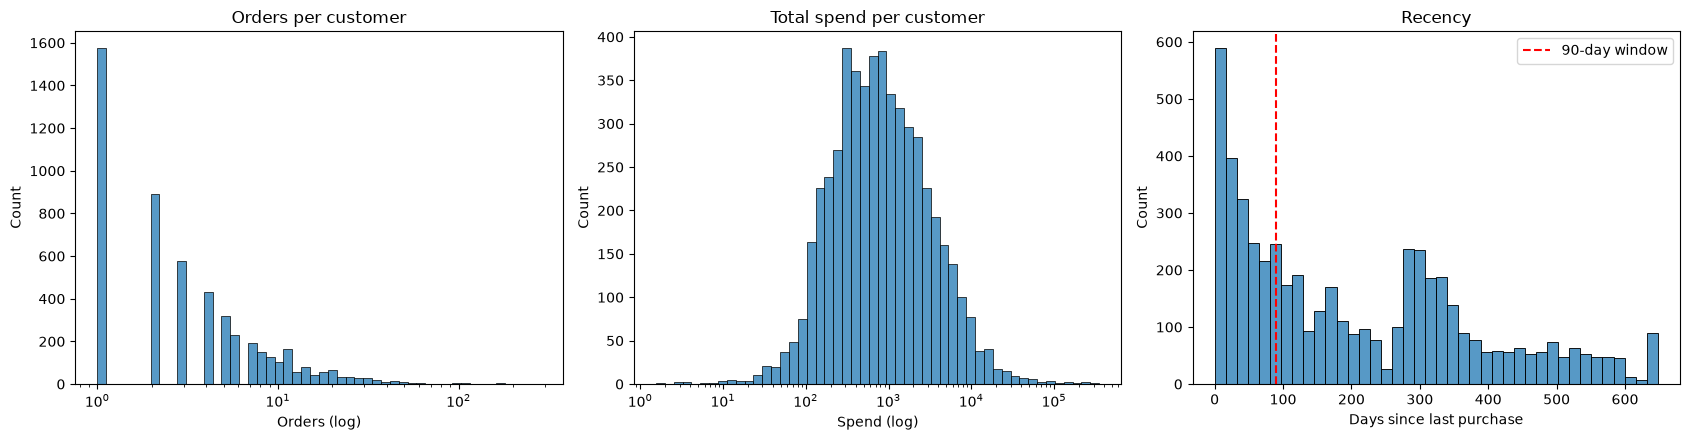

In [39]:
#Distributions: orders, spend, recency
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(cust["n_orders"], bins=50, log_scale=True, ax=axes[0])
axes[0].set(title="Orders per customer", xlabel="Orders (log)")

sns.histplot(cust["monetary"], bins=50, log_scale=True, ax=axes[1])
axes[1].set(title="Total spend per customer", xlabel="Spend (log)")

sns.histplot(cust["recency"], bins=40, ax=axes[2])
axes[2].axvline(CHURN_WINDOW_DAYS, color="red", ls="--", label=f"{CHURN_WINDOW_DAYS}-day window")
axes[2].set(title="Recency", xlabel="Days since last purchase")
axes[2].legend()
plt.tight_layout(); plt.show()


```python
Analysis:
```
Orders Per Customer: Most common value is a single order, at ~1,500-1,600 customers. About a 25-33% of the base, and it falls off steeply after that: ~900 customers have 2 orders, ~580 have 3, etc. The tail is very long, with a small group placing 100 or more orders. That group is probably wholesalers/resellers. Because so many customers are one-time buyers, it’s worth checking how their churn rate compares with repeat customers.

Total Spend Per Customer: Spend is roughly bell-shaped on the log axis. Most customers sit between about $100 and $10,000, with a peak around $300-$1,000. A good amount of customers spend $100k+. They're a small amount of customers but likely take up a large amount of revenue. NOTE: Use log-scaled spend, or a transform, in any model, because the raw values are far too skewed.

Recency: Recency
About 590 customers (tallest bar) bought within the last 25 days, and counts fall steadily after that.
There’s a second peak at about 280-340 days and this could be people who bought during the holidays and didn't return.

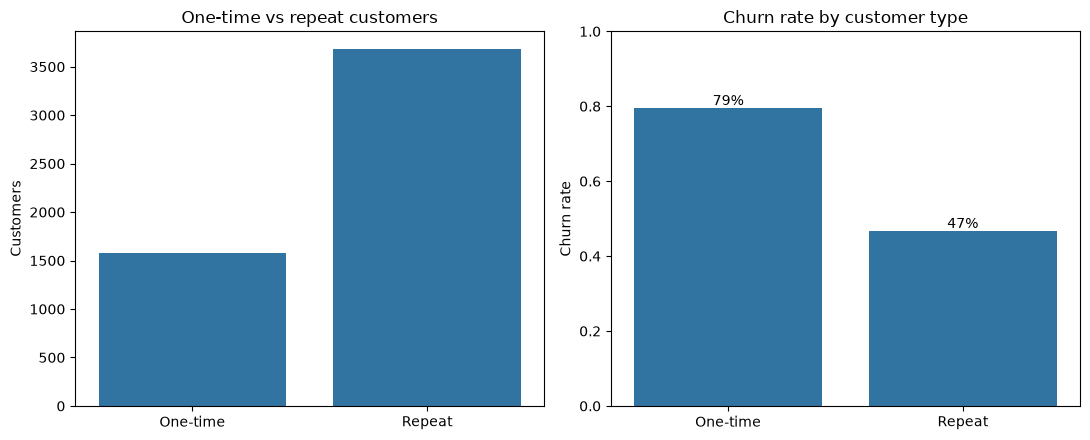

In [40]:
#One-time vs repeat customers (count + churn rate)
tmp = cust.assign(customer_type=np.where(cust["n_orders"] == 1, "One-time", "Repeat"))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.countplot(data=tmp, x="customer_type", order=["One-time", "Repeat"], ax=axes[0])
axes[0].set(title="One-time vs repeat customers", xlabel="", ylabel="Customers")
rate = tmp.groupby("customer_type")["churned"].mean().reindex(["One-time", "Repeat"]).reset_index()

sns.barplot(data=rate, x="customer_type", y="churned", ax=axes[1])
axes[1].set(title="Churn rate by customer type", xlabel="", ylabel="Churn rate", ylim=(0, 1))
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.0%}", (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")
plt.tight_layout(); plt.show()

```python
Analysis:
```
About 30% of customers (~1,570) bought only once, and 79% of them churned, compared with 47% of repeat customers. Overall churn is around 56%, so the classes are close to balanced. The 2nd purchase is the key retention point, but half of repeat customers still churn. One caveat is that "one-time" includes people who bought just before the cutoff and haven't had time to return, which makes the 79% look worse than it really is.

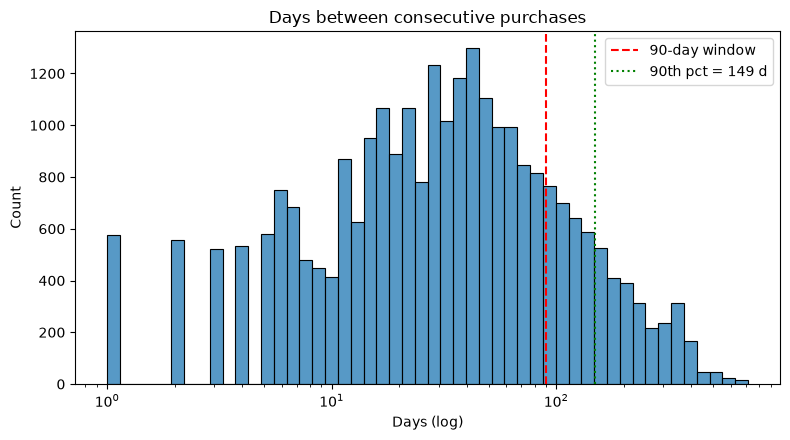

In [41]:
#Days between consecutive purchases (sanity-check the churn window)
orders = purch.groupby(["Customer ID", "Invoice"])["InvoiceDate"].min().reset_index()
orders = orders.sort_values(["Customer ID", "InvoiceDate"])
gaps = orders.groupby("Customer ID")["InvoiceDate"].diff().dt.days.dropna()
gaps = gaps[gaps > 0]
fig, ax = plt.subplots(figsize=(8, 4.5))

sns.histplot(gaps, bins=50, log_scale=True, ax=ax)
ax.axvline(CHURN_WINDOW_DAYS, color="red", ls="--", label=f"{CHURN_WINDOW_DAYS}-day window")
ax.axvline(gaps.quantile(0.9), color="green", ls=":", label=f"90th pct = {gaps.quantile(0.9):.0f} d")
ax.set(title="Days between consecutive purchases", xlabel="Days (log)")
ax.legend(); plt.tight_layout(); plt.show()

```python
Analysis:
```
Most repeat purchases happen within about 2-3 months of the previous one, with the peak around 30-50 days. The 90th percentile gap is 149 days. The tail runs past 300 days, which fits seasonal wholesale buyers who reorder only once or twice a year.

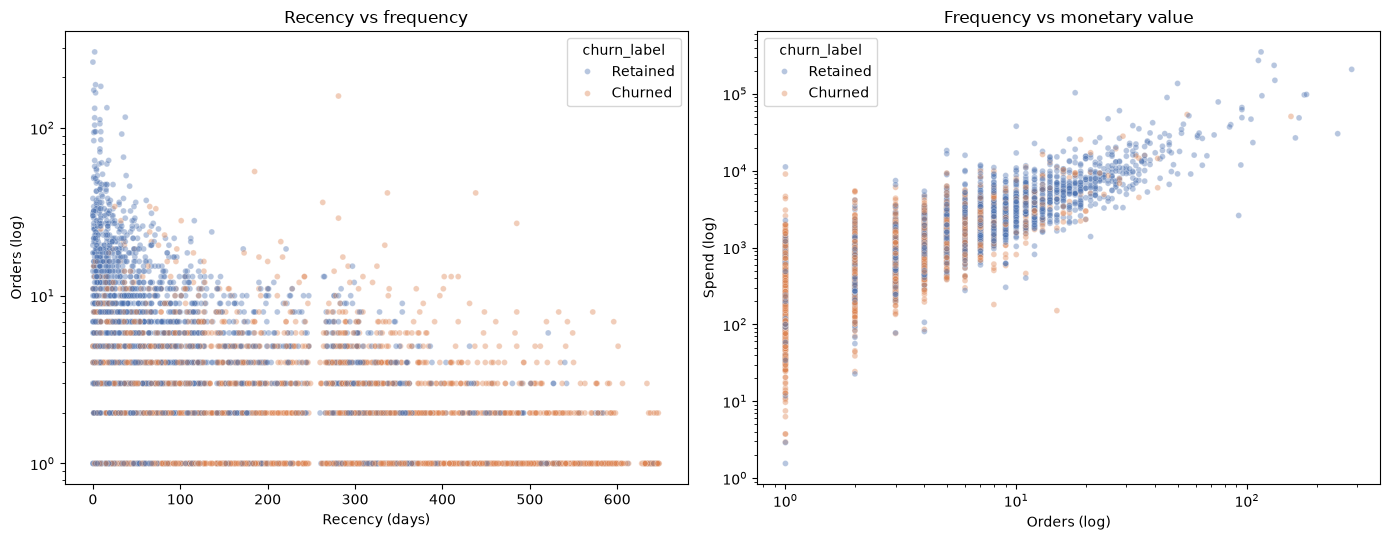

In [42]:
#Recency, Frequency, and Monetary scatter plots colored by churn
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

#Recency vs frequency
sns.scatterplot(data=cust, x="recency", y="n_orders", hue="churn_label", hue_order=HUE_ORDER,
                palette=PAL, alpha=0.4, s=18, ax=axes[0])
axes[0].set(yscale="log", title="Recency vs frequency", xlabel="Recency (days)", ylabel="Orders (log)")

#Frequency vs monetary value
sns.scatterplot(data=cust, x="n_orders", y="monetary", hue="churn_label", hue_order=HUE_ORDER,
                palette=PAL, alpha=0.4, s=18, ax=axes[1])
axes[1].set(xscale="log", yscale="log", title="Frequency vs monetary value",
            xlabel="Orders (log)", ylabel="Spend (log)")
plt.tight_layout(); plt.show()
 

```python
Analysis:
```
Recency Plot:
Retained customers cluster: they bought recently and order often, and almost no one with more than about 20 orders and recency under 100 days churned. Churned customers: spread out to the right with low order counts. There's heavy overlap among customers with 1 to 3 orders at every recency. Recency and frequency alone won't cleanly separate churn for that group. 

Monetary Value Plot:
Spend rises in line with order count. The two features carry similar information, and orange points sit mostly at 1 to 3 orders and low spend while the biggest spenders are almost all retained. A few high-order, high-spend customers did churn, and they are probably the most valuable losses to investigate.

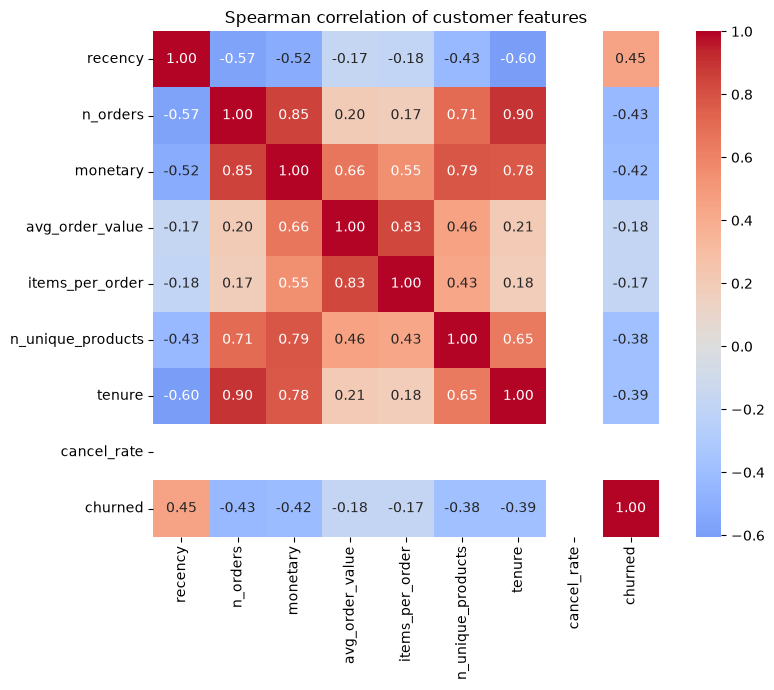

In [43]:
#Correlation heatmap
feats = ["recency", "n_orders", "monetary", "avg_order_value", "items_per_order",
         "n_unique_products", "tenure", "cancel_rate", "churned"]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cust[feats].corr(method="spearman"), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Spearman correlation of customer features")
plt.tight_layout(); plt.show()

```python
Analysis:
```
Recency has the strongest positive link to churn (0.45). Order count (-0.43), spend (-0.42), tenure (-0.39), and product variety (-0.38) all link to lower churn. So recent, frequent, long-standing customers stay. Average order value, items per order, and cancellation rate are only weakly related to churn (about -0.17 to -0.19). Many features overlap heavily: orders, spend, and tenure correlate at 0.78 to 0.90, so they carry similar information and will be redundant in a model. Cancellation rate rises a little with orders and spend (0.37 and 0.42), which means heavy buyers simply return more items. The returns on their own aren't a churn signal.

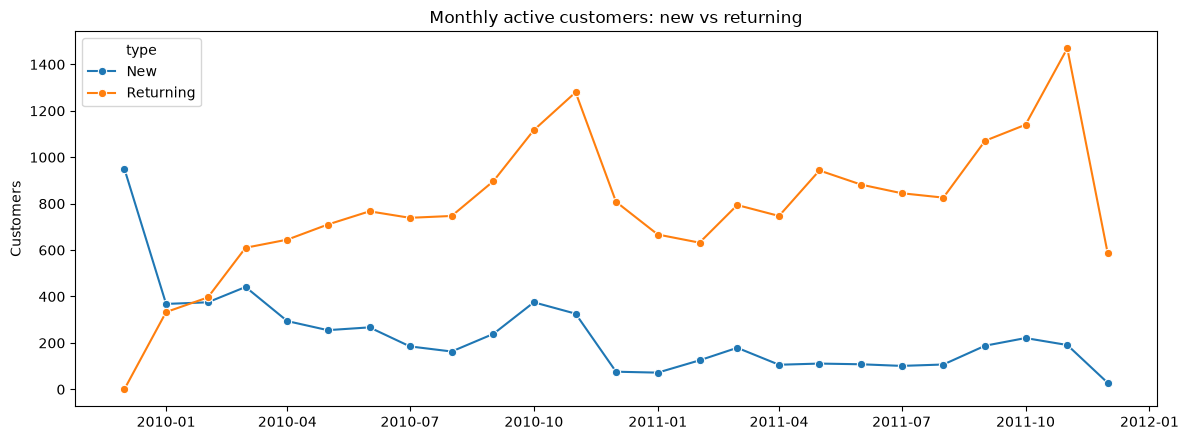

In [44]:
#Monthly active customers: new vs returning
cohort_df = purch.copy()   # rebuilt purchase dataframe
cohort_df["order_month"] = cohort_df["InvoiceDate"].dt.to_period("M")
cohort_df["cohort"] = (cohort_df.groupby("Customer ID")["InvoiceDate"]
                       .transform("min").dt.to_period("M"))
cohort_df["month_idx"] = ((cohort_df["order_month"].dt.year - cohort_df["cohort"].dt.year) * 12
                          + (cohort_df["order_month"].dt.month - cohort_df["cohort"].dt.month))
monthly = pd.DataFrame({
    "New": cohort_df[cohort_df["month_idx"] == 0].groupby("order_month")["Customer ID"].nunique(),
    "Returning": cohort_df[cohort_df["month_idx"] > 0].groupby("order_month")["Customer ID"].nunique(),
}).fillna(0).reset_index()
monthly["order_month"] = monthly["order_month"].dt.to_timestamp()
long = monthly.melt("order_month", var_name="type", value_name="customers")
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.lineplot(data=long, x="order_month", y="customers", hue="type", marker="o", ax=ax)
ax.set(title="Monthly active customers: new vs returning", xlabel="", ylabel="Customers")
plt.tight_layout(); plt.show()

```python
Analysis:
```
The spike of about 950 "new" customers in Dec 2009 is because the dataset starts that month and every active customer there looks new. After that, new customers per month drop from ~400 in early 2010 to ~100 by mid-2011 so acquisition is slowing and activity depends on returning customers. Both lines peak in Nov 2010 and Nov 2011 then falls afterwards, which is the seasonal activity that could be mistaken for churn if you don't account for it. The final drop in Dec 2011 is because the data ends around Dec 9, so that month is incomplete.

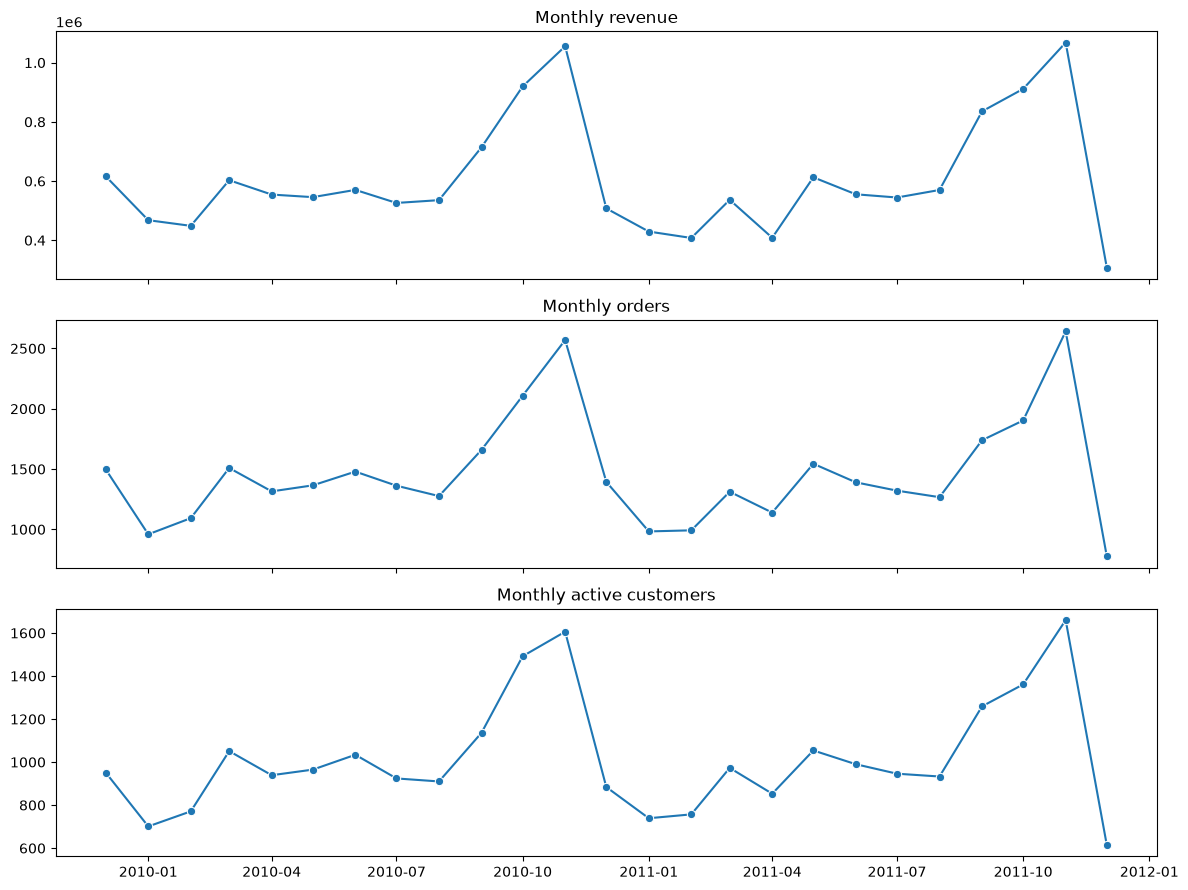

In [45]:
#Monthly revenue, orders, active customers
m = (purch.assign(month=purch["InvoiceDate"].dt.to_period("M").dt.to_timestamp())
     .groupby("month").agg(revenue=("Revenue", "sum"),
                           orders=("Invoice", "nunique"),
                           customers=("Customer ID", "nunique")).reset_index())
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, c, t in zip(axes, ["revenue", "orders", "customers"],
                    ["Monthly revenue", "Monthly orders", "Monthly active customers"]):
    sns.lineplot(data=m, x="month", y=c, marker="o", ax=ax)
    ax.set(title=t, xlabel="", ylabel="")
plt.tight_layout(); plt.show()

```python
Analysis:
```
Revenue, orders, and active customers move almost identically, which suggests revenue growth comes from more buyers and orders and not from bigger baskets. Each year follows the same pattern: a flat baseline of roughly $450k to $600k a month, then a ramp from September to a November peak of about $1.05M, about double normal, followed by a steep drop in Dec.

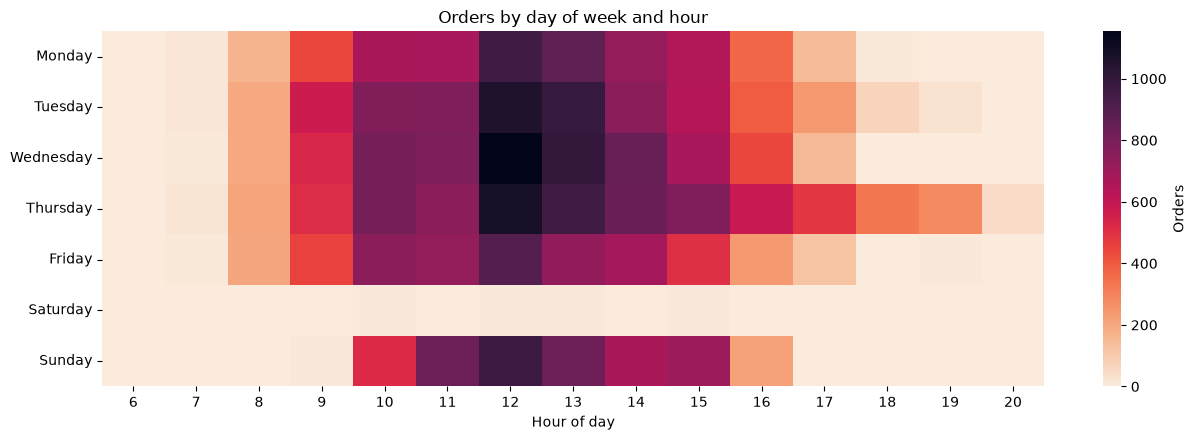

In [46]:
#Orders by day of week and hour
q = purch.assign(dow=purch["InvoiceDate"].dt.day_name(), hour=purch["InvoiceDate"].dt.hour)
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heat = (q.groupby(["dow", "hour"])["Invoice"].nunique().reset_index(name="orders")
        .pivot(index="dow", columns="hour", values="orders")
        .reindex([d for d in days if d in q["dow"].unique()]).fillna(0))
fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(heat, cmap="rocket_r", cbar_kws={"label": "Orders"}, ax=ax)
ax.set(title="Orders by day of week and hour", xlabel="Hour of day", ylabel="")
plt.tight_layout(); plt.show()

```python
Analysis:
```
Orders cluster on weekdays between about 10:00 and 15:00 and peak at noon, with Wednesday the busiest single slot then Tuesday and Thursday. That business-hours pattern fits a wholesale or B2B customer base more than casual consumers. Saturday has essentially no orders. Sunday is busy from 10:00 to 16:00. Thursday is the only day with meaningful evening activity between 17:00-20:00, and Friday tapers off earlier. Day and hour can add a little for predicting churn beyond being a scheduling context.

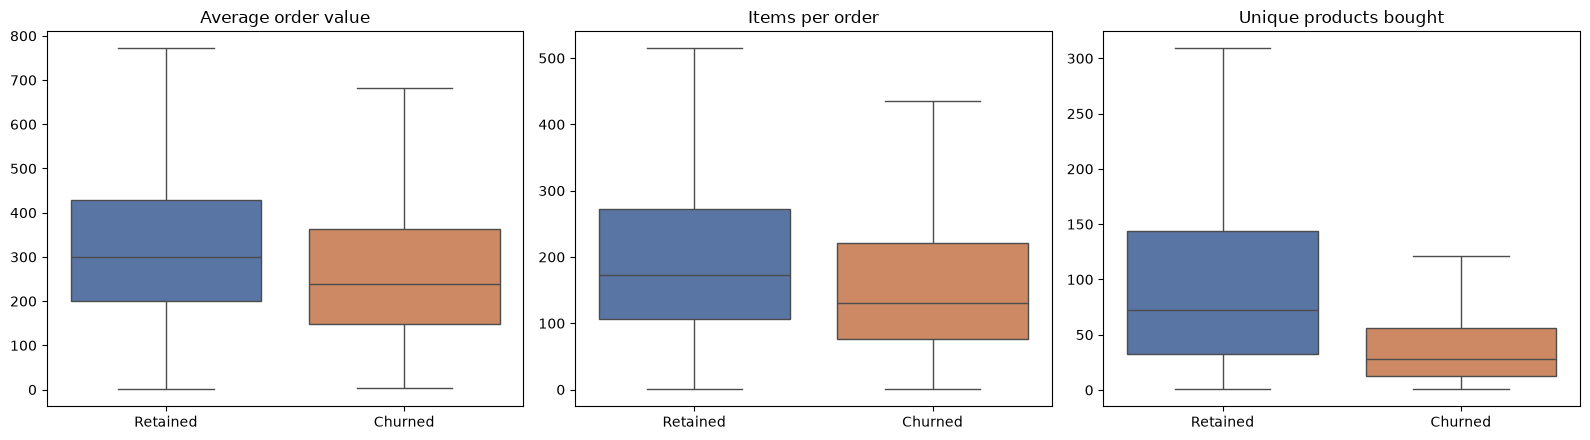

In [47]:
#Order behavior by churn (AOV, items per order, unique products)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, c, t in zip(axes, ["avg_order_value", "items_per_order", "n_unique_products"],
                    ["Average order value", "Items per order", "Unique products bought"]):
    sns.boxplot(data=cust, x="churn_label", y=c, order=HUE_ORDER, hue="churn_label",
                palette=PAL, legend=False, showfliers=False, ax=ax)
    ax.set(title=t, xlabel="", ylabel="")
plt.tight_layout(); plt.show()

```python
Analysis:
```
Retained customers sit higher on all three measures. Unique products bought has clearest separation, with a median of ~72 for retained customers versus ~28 for churned. Customers who buy a wider range of products tend to stay, but this is partly because product variety grows with the number of orders (correlation 0.71 earlier), so it may not add much beyond order count. Outliers are hidden in these plots, so the extreme high-value customers are not shown.

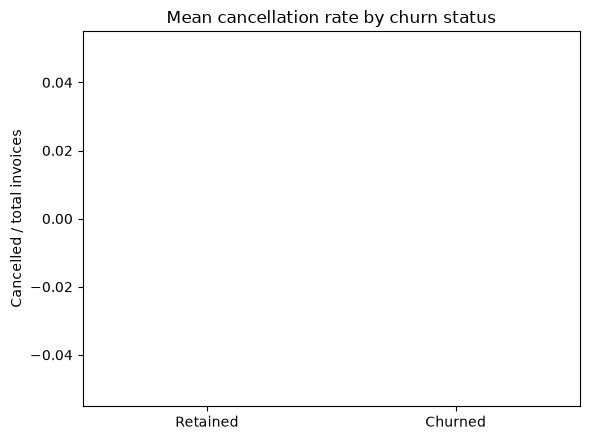

In [48]:
#Cancellation rate by churn
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.barplot(data=cust, x="churn_label", y="cancel_rate", order=HUE_ORDER, hue="churn_label",
            palette=PAL, legend=False, errorbar=("ci", 95), ax=ax)
ax.set(title="Mean cancellation rate by churn status", xlabel="", ylabel="Cancelled / total invoices")
plt.tight_layout(); plt.show()

```python
Analysis:
```
Retained customers have a higher average cancellation rate than churned ones. The confidence intervals don't overlap so the difference is likely real, although the gap is only 3-4%. It is possible that cancellation rate rises with activity (correlation of about 0.37 with order count). Customers who place many orders have more chances to cancel one, while one-time customers, who mostly churn, have a rate of zero. So cancellations can be seen as a marker of activity than as a churn warning. Need to compare customers with similar order counts to see whether returns matter on their own.

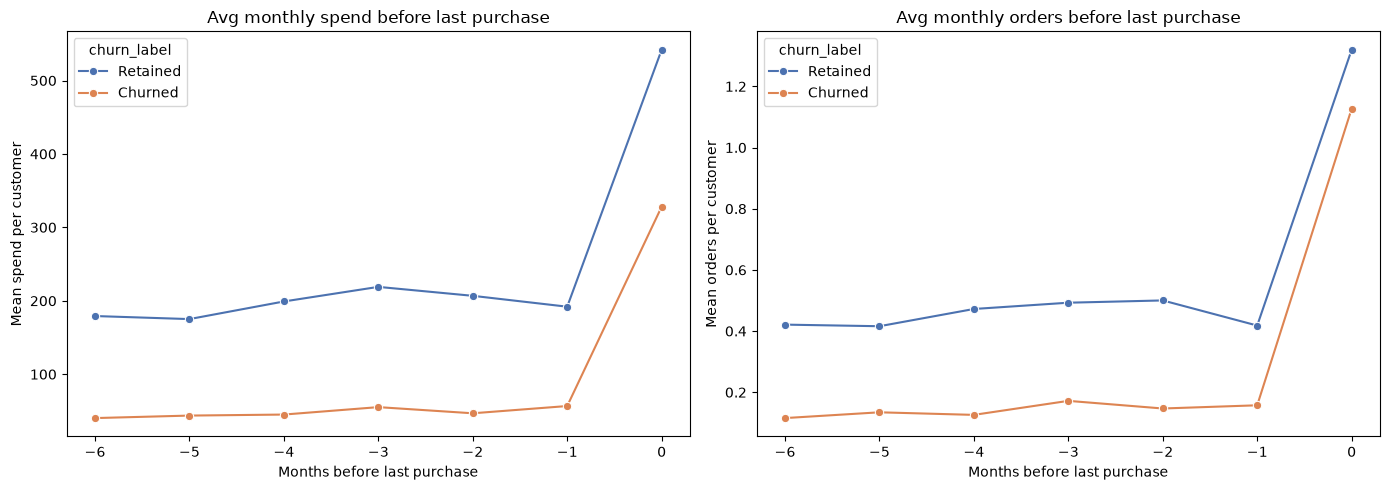

In [49]:
#Spend and orders leading up to a customer's last purchase
N_MONTHS = 6
t = purch.merge(cust[["Customer ID", "last_purchase", "churn_label"]], on="Customer ID")
t["months_before_last"] = ((t["last_purchase"].dt.year - t["InvoiceDate"].dt.year) * 12
                           + (t["last_purchase"].dt.month - t["InvoiceDate"].dt.month))
t = t[t["months_before_last"].between(0, N_MONTHS)]
lab = cust.set_index("Customer ID")["churn_label"]
 
def wide_to_long(values, aggfunc, name):
    w = (t.pivot_table(index="Customer ID", columns="months_before_last",
                       values=values, aggfunc=aggfunc)
         .reindex(cust["Customer ID"]).fillna(0))
    out = w.join(lab).melt(id_vars="churn_label", var_name="months_before_last", value_name=name)
    out["months_before_last"] = -out["months_before_last"].astype(int)
    return out
 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.lineplot(data=wide_to_long("Revenue", "sum", "spend"), x="months_before_last", y="spend",
             hue="churn_label", hue_order=HUE_ORDER, palette=PAL, marker="o",
             errorbar=None, ax=axes[0])
axes[0].set(title="Avg monthly spend before last purchase",
            xlabel="Months before last purchase", ylabel="Mean spend per customer")
sns.lineplot(data=wide_to_long("Invoice", "nunique", "orders"), x="months_before_last", y="orders",
             hue="churn_label", hue_order=HUE_ORDER, palette=PAL, marker="o",
             errorbar=None, ax=axes[1])
axes[1].set(title="Avg monthly orders before last purchase",
            xlabel="Months before last purchase", ylabel="Mean orders per customer")
plt.tight_layout(); plt.show()

```python
Analysis:
```
Churned customers were never very active as their monthly spend stays around $40-$55 and their orders at about 0.12 to 0.17 per month. Retained group's $175 to $220 and 0.42 to 0.50. There's no gradual decline before they leave so the churn shows up as a lower baseline activity level, not a falling trend we could use as an early warning. The jump at month 0 is built into the plot, because it is anchored on each customer's last purchase month, so it isn't a real surge. Months before a customer's first purchase count as zero, so newer customers and one-time buyers pull the churned averages down, which exaggerates the gap somewhat.

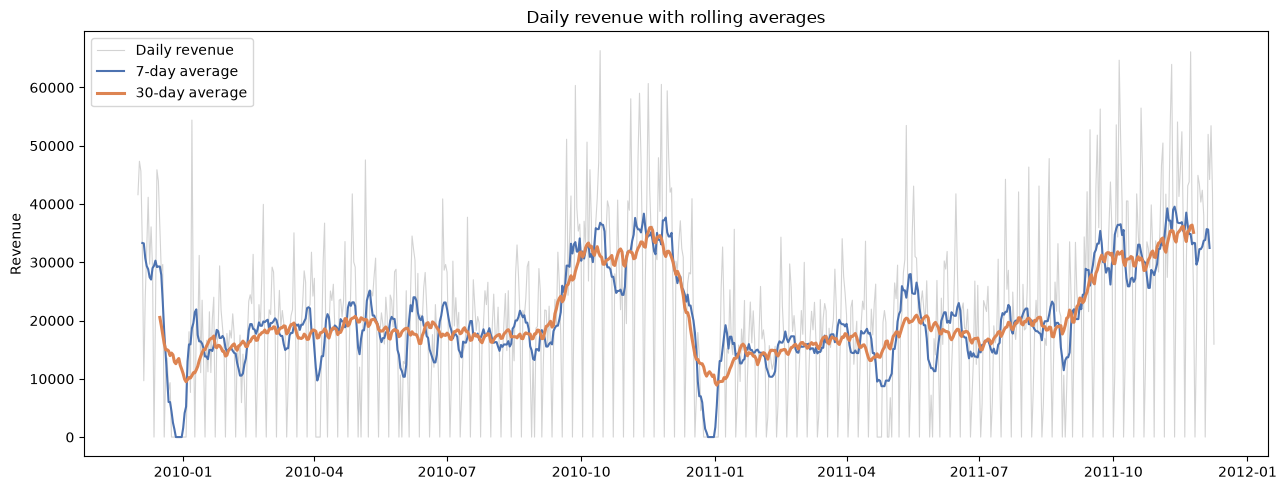

In [50]:
#Rolling averages (daily revenue smoothed over 7 and 30 days)
daily = (purch.assign(day=purch["InvoiceDate"].dt.normalize())
         .groupby("day")["Revenue"].sum().asfreq("D", fill_value=0))
roll = pd.DataFrame({"Daily revenue": daily,
                     "7-day average": daily.rolling(7, center=True).mean(),
                     "30-day average": daily.rolling(30, center=True).mean()}).reset_index()
long = roll.melt("day", var_name="series", value_name="revenue")
fig, ax = plt.subplots(figsize=(13, 5))
sns.lineplot(data=long[long["series"] == "Daily revenue"], x="day", y="revenue",
             color="lightgray", linewidth=0.8, label="Daily revenue", ax=ax)
sns.lineplot(data=long[long["series"] == "7-day average"], x="day", y="revenue",
             color="#4C72B0", label="7-day average", ax=ax)
sns.lineplot(data=long[long["series"] == "30-day average"], x="day", y="revenue",
             color="#DD8452", linewidth=2.2, label="30-day average", ax=ax)
ax.set(title="Daily revenue with rolling averages", xlabel="", ylabel="Revenue")
plt.tight_layout(); plt.show()

```python
Analysis:
```
Daily revenue is very noisy, with frequent drops to zero. The 30-day average shows a clear pattern of a stable baseline of about $15k to $20k a day, and a rise to roughly $30k to $35k from Sept to Nov in both years. There's a sharp fall to about $10k in late Dec each year, which is likely a holiday shutdown, and the 7-day line even touches zero around then. The Q4 peaks are similar in both years, with 2011 slightly higher, so growth is modest. The last few days of the series are partial and shouldn't be read as a trend.

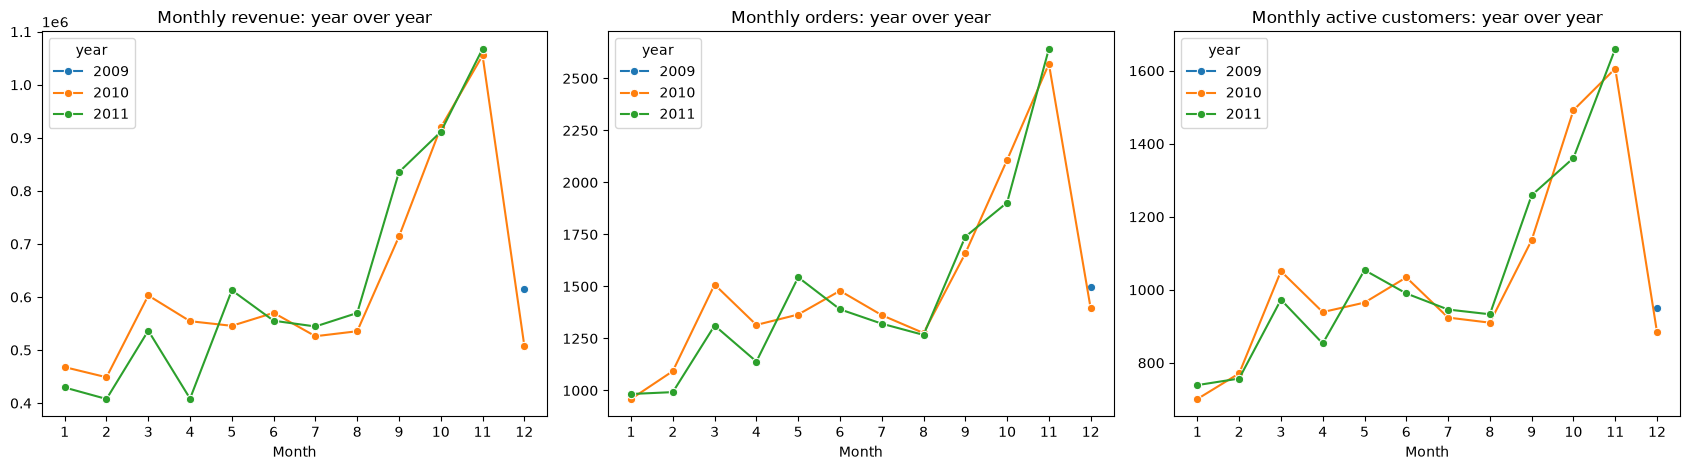

In [51]:
#Year-over-year overlay (same month, different years)
mm = (purch.assign(period=purch["InvoiceDate"].dt.to_period("M"))
      .groupby("period").agg(revenue=("Revenue", "sum"),
                             orders=("Invoice", "nunique"),
                             customers=("Customer ID", "nunique")).reset_index())
last_day = purch["InvoiceDate"].max().normalize()
if last_day < last_day.to_period("M").end_time.normalize():   # drop the partial final month
    mm = mm.iloc[:-1]
mm["year"] = mm["period"].dt.year.astype(str)
mm["month"] = mm["period"].dt.month
 
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, c, t in zip(axes, ["revenue", "orders", "customers"],
                    ["Monthly revenue", "Monthly orders", "Monthly active customers"]):
    sns.lineplot(data=mm, x="month", y=c, hue="year", marker="o", ax=ax)
    ax.set(title=f"{t}: year over year", xlabel="Month", ylabel="", xticks=range(1, 13))
plt.tight_layout(); plt.show()

```python
Analysis:
``` 
Note: Dropped the partial final month (the data ends around Dec 9, 2011), since a partial month would look like a sudden drop in revenue, orders, and active customers.

The 2010 and 2011 lines nearly overlap on revenue, orders, and active customers, so the seasonal pattern repeats. Year-over-year growth is minimal, since 2011 is slightly higher in Sept and Nov but lower in spring (Apr). The Q4 surge is therefore a normal yearly cycle, so a customer who goes quiet after November isn't necessarily churning. The lone 2009 point is just December 2009, and December 2011 is left out because it is a partial month.
